# Option A trial: Comma v0.1 with completion-style prompts

**Project:** Feature norms from a Nelson-free open-source large language model (LLM), extending De Deyne et al. (2026) and Liu, Shrestha & Huang (2026, ALIGN).
**Trial date:** November 2026 · **Status:** pilot, not results

## Context carried over from the planning conversation

- **Why Comma.** We cannot use a model whose training data has seen the Nelson, McEvoy & Schreiber (2004) University of South Florida (USF) free association norms. Comma v0.1 (7 billion parameters, Llama 3 architecture) was trained only on openly licensed text from the Common Pile, which makes exposure less likely. **The Nelson audit (pipeline Stage 1) has not been run yet**, so everything here is provisional.
- **Why "Option A".** Comma is a base model with no instruction tuning, so the prompt is written as a document for the model to continue, not as a chat instruction. Option B (OLMo 3 7B Instruct, instruction-style prompts like the anchor papers) is the alternative the advisor will choose between.
- **What this trial does.** It repeats Arm A of the subs2strudel pilot (LLM as virtual participant) with Comma instead of llama3.1, on the same four concepts (dog, chair, apple, happiness), 20 runs per concept at temperature 0.9.
- **What it adds.** Every output is scored three ways, to give an early read on pipeline Stage 4 (processing model output like human responses):
  1. **Phrase, substring match:** the pilot's original method.
  2. **Lemma, model side only:** model phrases reduced to content-word lemmas; human features left as published.
  3. **Lemma, both sides:** human features lemmatized the same way (advisor open question 4).

**Coverage metric (pipeline Stage 6):** the share of the human top-10 feature percentages that the model recovers.

$$\text{coverage}_c = 100 \times \frac{\sum_{f \in \text{top10}_c \cap \text{model}_c} p_{c,f}}{\sum_{f \in \text{top10}_c} p_{c,f}}$$

where $p_{c,f}$ is the percentage of human participants who listed feature $f$ for concept $c$.

## Run order

1. Environment check and setup (one time)
2. Download Comma and convert it to a 4-bit version (one time)
3. Settings
4. Load the human norms
5. Build the prompt
6. Generate 20 runs per concept
7. Parse and aggregate
8. Score coverage three ways
9. Compare with the llama3.1 pilot and plot
10. Save outputs
11. Reflection log
12. Memorization probe (audit, tier 1)
13. Software citations

## 1. Environment check and setup

Comma at full precision is about 14 GB on disk. The 4-bit version is about 4 GB and runs on Apple Silicon through Apple's MLX library. Check memory and free disk space first: you need roughly 20 GB free during conversion, and 16 GB of unified memory is comfortable.

**Recommended:** run this notebook in a fresh environment so it does not touch `venvs` or `mlp_env`. In a terminal:

```bash
python3 -m venv ~/venvs/comma-trial
source ~/venvs/comma-trial/bin/activate
pip install "mlx-lm>=0.20" spacy pandas matplotlib ipykernel
python -m spacy download en_core_web_sm
python -m ipykernel install --user --name comma-trial
```

Then select the **comma-trial** kernel in VS Code (top right of the notebook).

In [2]:
# Machine check: unified memory (GB) and free disk space in this folder.
import platform
import shutil
import subprocess

memory_bytes = int(subprocess.run(["sysctl", "-n", "hw.memsize"],
                                  capture_output=True, text=True).stdout.strip())
disk = shutil.disk_usage(".")

print(f"Machine:      {platform.machine()} ({platform.system()})")
print(f"Memory:       {memory_bytes / 1e9:.0f} GB")
print(f"Free disk:    {disk.free / 1e9:.0f} GB")

if memory_bytes / 1e9 < 16:
    print("Note: under 16 GB of memory. The 4-bit model should still run, but close other apps.")
if disk.free / 1e9 < 20:
    print("Warning: under 20 GB free. Conversion needs the full-precision download plus the 4-bit copy.")

Machine:      arm64 (Darwin)
Memory:       69 GB
Free disk:    553 GB


In [3]:
# Confirm the packages are importable in this kernel.
import importlib

for package_name in ["mlx", "mlx_lm", "spacy", "pandas", "matplotlib"]:
    try:
        module = importlib.import_module(package_name)
        print(f"{package_name:12s} OK   {getattr(module, '__version__', '')}")
    except ImportError:
        print(f"{package_name:12s} MISSING  -> see the setup commands above")

mlx          OK   
mlx_lm       OK   0.32.2
spacy        OK   3.8.18
pandas       OK   3.1.0
matplotlib   OK   3.11.2


In [4]:
import sys; print(sys.executable)


/Users/addieclark/venvs/comma-trial/bin/python


## 2. Download Comma and convert to 4-bit (one time)

This downloads the full-precision model from Hugging Face (about 14 GB) and writes a 4-bit copy to `models/`. It only needs to run once; later runs skip it.

We use **comma-v0.1-2t** (trained on 2 trillion tokens). The 1T version saw the same openly licensed data for fewer tokens; switch `HF_MODEL_ID` in the settings cell if the advisor prefers it.

In [5]:
from pathlib import Path

HF_MODEL_ID = "common-pile/comma-v0.1-2t"         # source model on Hugging Face
LOCAL_MODEL_DIR = Path("models/comma-v0.1-2t-4bit")  # 4-bit copy written here

if LOCAL_MODEL_DIR.exists():
    print(f"4-bit model already at {LOCAL_MODEL_DIR}, skipping conversion.")
else:
    LOCAL_MODEL_DIR.parent.mkdir(parents=True, exist_ok=True)
    # -q quantizes to 4 bits (the mlx_lm default bit width).
    !python -m mlx_lm convert --hf-path {HF_MODEL_ID} --mlx-path {LOCAL_MODEL_DIR} -q

[INFO] Loading
Reconstructing (incomplete total...): |           |  0.00B /  0.00B            

Fetching 9 files:   0%|                                  | 0/9 [00:00<?, ?it/s]Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.

Reconstructing (incomplete total...):   0%|       |  0.00B /   680B            

Fetching 9 files:  11%|██▉                       | 1/9 [00:00<00:02,  2.83it/s]
Reconstructing (incomplete total...):   0%|       |   680B / 9.97GB            
Reconstructing (incomplete total...):   0%|       |   680B / 14.0GB            
Reconstructing (incomplete total...):   0%|       |   680B / 14.0GB            
Reconstructing (incomplete total...):   0%|       |   680B / 14.0GB            
Reconstructing (incomplete total...):   0%|       | 24.6kB / 14.0GB            

Fetching 9 files:  33%|████████▋                 | 3/9 [00:00<00:00,  7.43it/s]
Reconstructing (incomplete total...):   0%| 

## 3. Settings

Everything you might change lives here. Sampling settings match the llama3.1 pilot so the comparison is like for like.

In [37]:
# --- Concepts (same four as the subs2strudel pilot) ---
CONCEPTS = ["dog", "chair", "apple", "happiness"]

# --- Sampling (matches the llama3.1 pilot) ---
RUNS_PER_CONCEPT = 100     # each run stands in for one "participant" (De Deyne et al. used 100)
TEMPERATURE = 0.9
MAX_NEW_TOKENS = 80        # enough for one feature list; output is cut at the first newline
BASE_SEED = 2026           # run i uses seed BASE_SEED + i, so results are reproducible

# --- Scoring ---
TOP_K_HUMAN = 10           # coverage uses the human top-10 features per concept
MIN_MODEL_PERCENT = 10     # a model feature counts only if >= 10% of runs (10 of 100) produced it

# --- Human norms file (edit the path and column names to match your copy) ---
HUMAN_NORMS_PATH = Path("copy_english_Buchanan2019.csv")
CONCEPT_COLUMN = "cue"                  # concept (cue first)
FEATURE_COLUMN = "feature"              # feature word (target last)
PERCENT_COLUMN = "normalized_feature"   # % of participants listing the feature

# --- Outputs (one folder per run, so earlier runs are never overwritten) ---
RUN_LABEL = "run03b_pos_filters"   # change this before every new run
OUTPUT_DIR = Path("outputs/option_a_trial") / RUN_LABEL
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 4. Load the human norms (Buchanan et al., 2019)

The column names in the settings cell are a best guess. If this cell fails, look at the printed column list and fix `CONCEPT_COLUMN`, `FEATURE_COLUMN` and `PERCENT_COLUMN`.

If the percentage column is a proportion (0 to 1) rather than a percentage, the cell rescales it.

In [12]:
import pandas as pd

human_raw = pd.read_csv(HUMAN_NORMS_PATH)
print("Columns in the file:", list(human_raw.columns))
print("Rows per source (where):", human_raw["where"].value_counts().to_dict())

# Keep only concept, feature and percentage (concept first, feature last).
human = (human_raw[[CONCEPT_COLUMN, PERCENT_COLUMN, FEATURE_COLUMN]]
         .rename(columns={CONCEPT_COLUMN: "concept",
                          PERCENT_COLUMN: "percent",
                          FEATURE_COLUMN: "feature"}))
human["concept"] = human["concept"].astype(str).str.lower().str.strip()
human["feature"] = human["feature"].astype(str).str.lower().str.strip()

# Rescale proportions to percentages if needed.
if human["percent"].max() <= 1:
    human["percent"] = human["percent"] * 100

# Keep only the trial concepts.
human = human[human["concept"].isin(CONCEPTS)]

# The file merges several norm sets, so a feature can appear more than once per concept
# (e.g., apple lists 'red' three times). Keep each feature once, at its highest
# percentage, to match the subs2strudel pilot.
human = (human.groupby(["concept", "feature"], as_index=False)["percent"].max()
              [["concept", "percent", "feature"]])

# Take each concept's top-K features.
human_top = (human.sort_values(["concept", "percent"], ascending=[True, False])
                  .groupby("concept").head(TOP_K_HUMAN)
                  .reset_index(drop=True))

missing = set(CONCEPTS) - set(human_top["concept"])
if missing:
    print("Warning: no human norms found for", sorted(missing))

human_top

Columns in the file: ['where', 'cue', 'feature', 'translated', 'frequency_feature', 'frequency_translated', 'n', 'normalized_feature', 'normalized_translated', 'pos_cue', 'pos_feature', 'pos_translated', 'a1', 'a2', 'a3', 'FSG', 'BSG', 'word_list', 'school_code']
Rows per source (where): {'b': 48925, 'v': 12053, 'm': 8306}


,concept,percent,feature
0,apple,95.000000,fruit
1,apple,90.000000,red
2,apple,66.666667,grow
3,apple,66.666667,trees
4,apple,58.000000,green
5,apple,55.000000,tree
6,apple,36.666667,crunchy
7,apple,36.666667,eat
8,apple,36.666667,pies
9,apple,35.000000,health


## 5. Build the completion-style prompt

Comma has no chat mode, so the prompt is a short document: a header explaining the task, the Buchanan worked examples, then the target concept followed by a colon. The model continues the line.

**Paste the cucumber and stove examples** from `materials/human/english_Buchanan2019.html` into `WORKED_EXAMPLES`. Only the duck example (from the pilot memo) is filled in here; empty examples are skipped, and the cell warns you.

The header wording is ours, not Buchanan's. It is logged in Section 11.

In [23]:
PROMPT_HEADER = (
    "In this task, people list the properties of familiar things: what they look like, "
    "what they are made of, what they do, what they are used for, and what kind of thing they are. "
    "Each line gives a word followed by a comma-separated list of its properties.\n\n"
)

# Worked examples from the Buchanan et al. (2019) instructions.
WORKED_EXAMPLES = {
    "duck": ("is a bird, is an animal, waddles, flies, migrates, lays eggs, quacks, swims, "
             "has wings, has a beak, has webbed feet, has feathers, lives in ponds, "
             "lives in water, hunted by people, is edible"),
    "cucumber": ("is a vegetable, has green skin, has a white inside, has seeds, "
                 "is cylindrical, is long, grows in gardens, grows on vines, is edible, "
                 "is crunchy, used for making pickles, eaten in salads"),
    "stove": ("is an appliance, produces heat, inside has elements, inside has an oven, "
              "made of metal, is hot, is electrical, runs on wood, runs on gas, "
              "found in kitchens, used for baking, used for cookng food"),
}
def build_prompt(concept):
    # Header, then one line per worked example, then the target concept (cue last in prompt, open slot).
    example_lines = [f"{word}: {features}"
                     for word, features in WORKED_EXAMPLES.items() if features]
    return PROMPT_HEADER + "\n".join(example_lines) + f"\n{concept}:"


skipped = [word for word, features in WORKED_EXAMPLES.items() if not features]
if skipped:
    print("Warning: these worked examples are empty and were skipped:", skipped, "\n")

print(build_prompt("dog"))

In this task, people list the properties of familiar things: what they look like, what they are made of, what they do, what they are used for, and what kind of thing they are. Each line gives a word followed by a comma-separated list of its properties.

duck: is a bird, is an animal, waddles, flies, migrates, lays eggs, quacks, swims, has wings, has a beak, has webbed feet, has feathers, lives in ponds, lives in water, hunted by people, is edible
cucumber: is a vegetable, has green skin, has a white inside, has seeds, is cylindrical, is long, grows in gardens, grows on vines, is edible, is crunchy, used for making pickles, eaten in salads
stove: is an appliance, produces heat, inside has elements, inside has an oven, made of metal, is hot, is electrical, runs on wood, runs on gas, found in kitchens, used for baking, used for cookng food
dog:


## 6. Generate 20 --> 100 runs per concept

Each run uses its own random seed. The output is cut at the first newline, because a base model will keep writing new lines for other words.

On a recent Apple Silicon Mac this should take a few minutes in total.

In [30]:
import mlx.core as mx
from mlx_lm import load, generate
from mlx_lm.sample_utils import make_sampler

model, tokenizer = load(str(LOCAL_MODEL_DIR))
sampler = make_sampler(temp=TEMPERATURE)

generation_log = []   # one row per run: the prompt log for the reflection section

for concept in CONCEPTS:
    prompt = build_prompt(concept)
    for run_index in range(RUNS_PER_CONCEPT):
        seed = BASE_SEED + run_index
        mx.random.seed(seed)
        raw_output = generate(model, tokenizer, prompt=prompt,
                              max_tokens=MAX_NEW_TOKENS, sampler=sampler)
        first_line = raw_output.split("\n")[0].strip()
        generation_log.append({"concept": concept, "run": run_index, "seed": seed,
                               "raw_output": raw_output, "feature_line": first_line})
    print(f"{concept}: done")

generations = pd.DataFrame(generation_log)
generations[["concept", "run", "feature_line"]].head(10)

dog: done
chair: done
apple: done
happiness: done


,concept,run,feature_line
0,dog,0,"is an animal, has hooved feet, is four-legged,..."
1,dog,1,"is a animal, is a dog, has fur, has four legs,..."
2,dog,2,"is a animal, has four legs, has fur, barks, bi..."
3,dog,3,"is furry, has tail, is domesticated, is wild, ..."
4,dog,4,"is an animal, is a mammal, is four-legged, has..."
5,dog,5,"is a dog, is an animal, is furry, has four leg..."
6,dog,6,"is a mammal, eats food, is a pet, is barking, ..."
7,dog,7,"is a pet, is used as a guide, is useful, is fo..."
8,dog,8,"is a pet, is an animal, is a mammal, sleeps, d..."
9,dog,9,"is a dog, is a animal, is housebroken, is dome..."


## 7. Parse and aggregate

Each feature line is split on commas. Within one run a feature counts once, then each feature's percentage is the share of runs that produced it, the same normalization as the human study.

The lemma condition reduces each phrase to content-word lemmas with spaCy (for example, `wags its tail` becomes `wag`, `tail`). The exact rules still need to be matched to the Buchanan pipeline (pipeline Stage 4).

In [38]:
import spacy
from collections import Counter

nlp = spacy.load("en_core_web_sm")


def split_features(feature_line):
    # 'barks, has fur, barks' -> ['barks', 'has fur']  (lowercase, no blanks, no repeats)
    seen = []
    for piece in feature_line.lower().split(","):
        piece = piece.strip(" .;:\"'")
        if piece and piece not in seen:
            seen.append(piece)
    return seen


# Parts of speech to drop: grammar words with no feature content
# ('is', 'a', 'it', 'and', 'to'). Numbers ('four') and prepositions ('on') are kept,
# because the human norms keep them as features.
DROP_POS = {"DET", "AUX", "PRON", "CCONJ", "SCONJ", "PART", "PUNCT", "SYM", "SPACE"}


def to_lemmas(phrase):
    # 'has four legs' -> ['have', 'four', 'leg']; 'sits on it' -> ['sit', 'on']
    return [token.lemma_.lower() for token in nlp(phrase)
            if token.is_alpha and token.pos_ not in DROP_POS]

def percent_of_runs(feature_lists, runs):
    # feature_lists: one list per run. Each feature counts once per run.
    counts = Counter(feature for features in feature_lists for feature in set(features))
    return {feature: 100 * count / runs for feature, count in counts.items()}


model_phrases = {}   # concept -> {phrase: % of runs}
model_lemmas = {}    # concept -> {lemma: % of runs}

for concept in CONCEPTS:
    lines = generations.loc[generations["concept"] == concept, "feature_line"]
    phrase_lists = [split_features(line) for line in lines]
    lemma_lists = [[lemma for phrase in phrases for lemma in to_lemmas(phrase)]
                   for phrases in phrase_lists]
    model_phrases[concept] = percent_of_runs(phrase_lists, RUNS_PER_CONCEPT)
    model_lemmas[concept] = percent_of_runs(lemma_lists, RUNS_PER_CONCEPT)

# Show each concept's most frequent model phrases.
for concept in CONCEPTS:
    top = sorted(model_phrases[concept].items(), key=lambda item: -item[1])[:8]
    print(f"{concept:10s}", ", ".join(f"{phrase} {pct:.0f}" for phrase, pct in top))

dog        is a pet 83, has fur 70, has a tail 54, has four legs 54, is an animal 43, is a mammal 40, barks 34, is furry 31
chair      has a back 71, has a seat 70, is a piece of furniture 66, has legs 46, is made of wood 37, used for sitting 28, made of wood 24, has arms 22
apple      is a fruit 94, is sweet 76, is edible 70, has seeds 68, is round 41, grows on trees 38, is red 36, is juicy 31
happiness  is a feeling 72, is an emotion 51, is a mood 37, is a state of mind 32, is subjective 30, is positive 26, is a state 14, is good 13


## 8. Score coverage three ways

Only model features produced in at least `MIN_MODEL_PERCENT` of runs count, so a feature one run happened to mention does not inflate coverage.

| Condition | Human side | Model side | Match rule |
| --- | --- | --- | --- |
| Phrase, substring | as published | whole phrase | human word appears as a word inside a model phrase (pilot method) |
| Lemma, model side only | as published | lemmas | exact match |
| Lemma, both sides | lemmatized | lemmas | exact match |

In [39]:
import re


def kept_features(feature_percents):
    # Model features produced in at least MIN_MODEL_PERCENT of runs.
    return {feature for feature, pct in feature_percents.items() if pct >= MIN_MODEL_PERCENT}


def phrase_covers(human_feature, phrases):
    # True if the human word appears as a whole word inside any model phrase.
    pattern = rf"\b{re.escape(human_feature)}\b"
    return any(re.search(pattern, phrase) for phrase in phrases)


def coverage(human_rows, is_covered):
    # Share (0-100) of human top-K percentage mass that the model recovers.
    total = human_rows["percent"].sum()
    covered = human_rows.loc[human_rows["feature"].apply(is_covered), "percent"].sum()
    return 100 * covered / total if total else float("nan")


coverage_rows = []
for concept in CONCEPTS:
    rows = human_top[human_top["concept"] == concept]
    phrases = kept_features(model_phrases[concept])
    lemmas = kept_features(model_lemmas[concept])

    coverage_rows.append({
        "concept": concept,
        "phrase_substring": coverage(rows, lambda f: phrase_covers(f, phrases)),
        "lemma_model_only": coverage(rows, lambda f: f in lemmas),
        "lemma_both_sides": coverage(rows, lambda f: any(l in lemmas for l in to_lemmas(f))),
    })

coverage_table = pd.DataFrame(coverage_rows).round(1)
coverage_table

,concept,phrase_substring,lemma_model_only,lemma_both_sides
0,dog,81.5,60.3,94.6
1,chair,55.4,40.2,69.5
2,apple,63.3,76.0,93.9
3,happiness,38.1,66.7,66.7


In [42]:
# Human top-10 features that to_lemmas reduces to nothing (so they can never be matched).
erased = human_top[human_top["feature"].apply(lambda feature: len(to_lemmas(feature)) == 0)]
erased

,concept,percent,feature


## 9. Compare with the llama3.1 pilot

The llama3.1 numbers come from the subs2strudel pilot memo (Arm A, phrase substring matching). That model has not been checked for Nelson exposure either, and the pilot's exact threshold for counting a model feature was not recorded, so treat this as a rough side-by-side.

,concept,llama31_pilot_phrase,phrase_substring,lemma_model_only,lemma_both_sides
0,dog,94.6,81.5,60.3,94.6
1,chair,94.3,55.4,40.2,69.5
2,apple,93.9,63.3,76.0,93.9
3,happiness,77.8,38.1,66.7,66.7


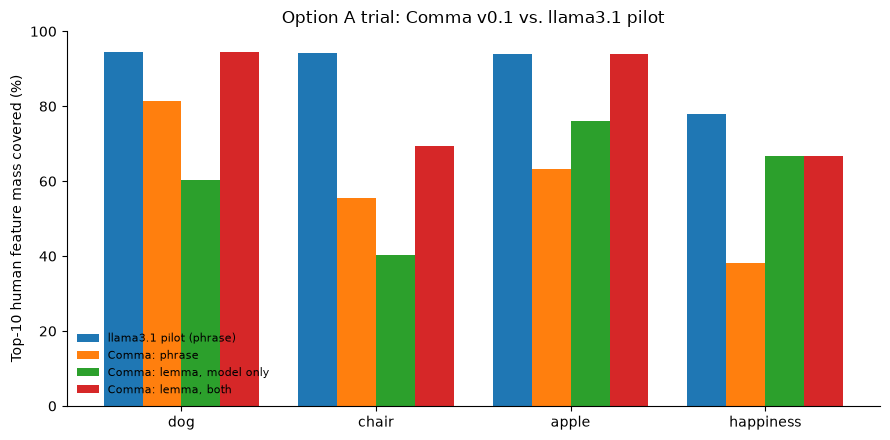

In [40]:
import matplotlib.pyplot as plt

LLAMA_PILOT_COVERAGE = {"dog": 94.6, "chair": 94.3, "apple": 93.9, "happiness": 77.8}

comparison = coverage_table.copy()
comparison.insert(1, "llama31_pilot_phrase", comparison["concept"].map(LLAMA_PILOT_COVERAGE))
display(comparison)

# Grouped bar chart: one group per concept, one bar per condition.
conditions = ["llama31_pilot_phrase", "phrase_substring", "lemma_model_only", "lemma_both_sides"]
labels = ["llama3.1 pilot (phrase)", "Comma: phrase", "Comma: lemma, model only", "Comma: lemma, both"]
bar_width = 0.2
x_positions = range(len(CONCEPTS))

fig, ax = plt.subplots(figsize=(9, 4.5))
for i, (column, label) in enumerate(zip(conditions, labels)):
    ax.bar([x + i * bar_width for x in x_positions], comparison[column], bar_width, label=label)

ax.set_xticks([x + 1.5 * bar_width for x in x_positions])
ax.set_xticklabels(CONCEPTS)
ax.set_ylabel("Top-10 human feature mass covered (%)")
ax.set_ylim(0, 100)
ax.set_title("Option A trial: Comma v0.1 vs. llama3.1 pilot")
ax.legend(frameon=False, fontsize=8, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "coverage_comparison.png", dpi=200)
plt.show()

## 10. Save outputs

- `generations.csv`: every raw output and parsed line, with its seed (the prompt log)
- `model_features.csv`: phrase and lemma percentages per concept, concept first and feature last
- `coverage.csv`: the comparison table
- `prompt_used.txt`: the exact prompt for one concept

In [41]:
generations.to_csv(OUTPUT_DIR / "generations.csv", index=False)

feature_rows = []
for concept in CONCEPTS:
    for unit, table in [("phrase", model_phrases[concept]), ("lemma", model_lemmas[concept])]:
        for feature, pct in table.items():
            feature_rows.append({"concept": concept, "unit": unit,
                                 "percent_of_runs": round(pct, 1), "feature": feature})
pd.DataFrame(feature_rows).to_csv(OUTPUT_DIR / "model_features.csv", index=False)

comparison.to_csv(OUTPUT_DIR / "coverage.csv", index=False)
(OUTPUT_DIR / "prompt_used.txt").write_text(build_prompt("{concept}"))

print("Saved to", OUTPUT_DIR.resolve())

Saved to /Users/addieclark/Desktop/Harrisburg/SPAML/subs2strudel/SCiP_2026/outputs/option_a_trial/run03b_pos_filters


## 11. Reflection log

### Prompt log

| Item | Value |
| --- | --- |
| Model | common-pile/comma-v0.1-2t, 4-bit MLX conversion (4.5 bits per weight) |
| Prompt style | Completion (Option A) |
| Header | Our wording (Section 5), not Buchanan's |
| Worked examples | duck, cucumber, stove, verbatim from `materials/human/english_Buchanan2019.html` (comma added after "is long"; "cookng" typo kept) |
| Runs × temperature | 100 × 0.9 per concept, seeds 2026–2125 (runs 1–2 used 20 runs, seeds 2026–2045) |
| Output cut | First line of each generation; up to 80 new tokens |
| Model feature threshold | ≥ 10% of runs (10 of 100) |
| Lemma rule | spaCy `en_core_web_sm` lemmas, part-of-speech filter (run 3b onward) |
| Human norms | `copy_english_Buchanan2019.csv`: `cue`, `feature`, `normalized_feature`; one row per concept–feature at its highest percentage |

### Run table

Coverage of the human top-10 feature mass, shown as phrase / lemma, model side only / lemma, both sides.

| Run | Worked examples | Runs per concept | Lemma rule | dog | chair | apple | happiness | Saved to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | duck only | 20 | stopwords | 79.9 / 50.5 / 84.8 | 61.1 / 36.0 / 71.0 | 69.6 / 76.0 / 87.6 | 30.2 / 54.0 / 54.0 | not saved |
| 2 | duck, cucumber, stove | 20 | stopwords | 88.0 / 50.5 / 78.3 | 55.4 / 35.8 / 65.0 | 63.3 / 76.0 / 87.6 | 38.1 / 66.7 / 66.7 | `run02_three_examples_20runs` |
| 3 | duck, cucumber, stove | 100 | stopwords | 81.5 / 50.5 / 84.8 | 55.4 / 30.3 / 59.5 | 63.3 / 76.0 / 93.9 | 38.1 / 66.7 / 66.7 | `run03_three_examples_100runs` |
| 3b | duck, cucumber, stove | 100 (same generations as run 3) | part of speech | 81.5 / 60.3 / 94.6 | 55.4 / 40.2 / 69.5 | 63.3 / 76.0 / 93.9 | 38.1 / 66.7 / 66.7 | `run03b_pos_filters` |

llama3.1 pilot (phrase scoring, threshold not recorded): dog 94.6, chair 94.3, apple 93.9, happiness 77.8.

### Debugging notes

1. **Section 4, file path.** The filename was typed without quotes, so Python read it as a variable name (`NameError`). Fixed by setting `HUMAN_NORMS_PATH` in Settings.
2. **Section 4, merged sources.** The CSV combines three norm sets (`where` = b, v, m), so features repeat within a concept (apple lists *red* three times). Kept one row per concept–feature at its highest percentage, which reproduces the pilot memo's human lists. Restricting to Buchanan's own rows (`b`) was not possible: *dog* has none.
3. **Section 4, Nelson values in the human file.** The `FSG` and `BSG` columns are the Nelson forward and backward association strengths (filled in for 28,172 of 69,284 rows). They are never loaded or shown to the model, but they mean a copy of this file is indirect Nelson exposure, so it is probed in Section 12.
4. **Section 7, spaCy stall.** The lemma cell was interrupted once while spaCy's parser was running (`KeyboardInterrupt`) and completed on rerun. If it stalls again: load spaCy with the parser and named-entity recognizer disabled and cache lemmas per phrase.
5. **Run 1, missing examples.** Run 1 used only the duck example because cucumber and stove were placeholders. With duck alone, outputs copied its "is a …" pattern (*is a pet*, *is a fruit*) and repeated the cue (*is a dog*, 60% of dog runs). Adding all three examples shifted outputs toward function and sensory features (*used for sitting*, *is sweet*), and *is a dog* fell to 35%.
6. **Threshold resolution at 20 runs.** Every change between runs 1 and 2 was exactly one human feature crossing the 2-of-20 threshold, so differences of 5–10 points were at the trial's resolution limit. Increased to 100 runs (as in De Deyne et al.) and gave each run its own output folder.
7. **Seed reproducibility.** Runs 0–19 of run 3 reproduce run 2 exactly because they reuse seeds 2026–2045, which confirms the seeding works.
8. **Stopword filter erased human features.** spaCy's stopword list removed *on* (chair, 86.7) and *four* (chair 63.3, dog 60), so they could never be matched in either lemma condition; this alone pushed chair below happiness. Replaced the stopword filter with a part-of-speech filter that drops only grammar words and keeps numbers and prepositions, then rescored the same generations as run 3b. Each change from 3 to 3b is exactly the *four* feature (about 10 points for dog and chair).

### Revision table

| Section | What AI returned | Accepted | What was changed |
| --- | --- | --- | --- |
| 4. Load human norms | Load `cue`, `feature`, `normalized_feature`; take top 10 | Yes | Added one-row-per-feature step (highest percentage) after the merged-source duplicates were found |
| 5. Prompt header | Header sentence describing the task | Yes | Used unchanged in all runs |
| 5. Worked examples | Duck only, with placeholders for cucumber and stove | Yes | Cucumber and stove pasted verbatim from the instructions page; comma added after "is long"; "cookng" kept |
| 3. Settings | 20 runs per concept, one output folder | Yes | 100 runs per concept; one output folder per run (`RUN_LABEL`) |
| 7. Lemma rules | spaCy content-word lemmas, stopwords removed | Yes, then revised | Stopword filter replaced with a part-of-speech filter (keeps numbers and prepositions); run 3 rescored as run 3b |
| 8. Threshold | 10% of runs | Yes | Unchanged; now means 10 of 100 runs |
| 8. Check cell | Lists human features the lemma rule erases | Yes | Added after run 3; empty from run 3b onward |

### Findings so far (pilot, not results)

1. **Lemmatizing only the model side scores lowest for dog and chair in every run.** The human norms keep inflected forms (*barks*, *legs*, *sitting*), so the model's lemmas stop matching them. Lemmatizing both sides is the fair comparison.
2. **The lemma rule itself moves results.** spaCy's default stopword list cost about 10 points on two of four concepts. The rule has to match Buchanan's processing, not a library default.
3. **Concrete above abstract under lemma, both sides (run 3b):** dog 94.6, apple 93.9, chair 69.5, happiness 66.7. Chair's remaining gap is mostly *on* (86.7): matchable now, but Comma says "used for sitting" rather than "sit on".
4. **Prompt examples shape output style.** One example produced category-heavy lists; three examples produced a mix closer to human feature types.

### Things to check before showing these numbers

1. The Nelson audit on Comma's training data (pipeline Stage 1) is in progress: Section 12 is tier 1 (memorization probe); tier 2 (corpus search) depends on the exposure standard the advisor sets.

### Audit log

| Date | Tier | File | Positions × rows | Exact rows | Novel values correct (not in shown rows) | Reading |
| --- | --- | --- | --- | --- | --- | --- |
| 2026-11-03 | 1 (memorization probe) | Buchanan CSV | 20 × 3 | 0% | 0 / 130 (feature 0/59, normalized_feature 0/43, FSG 0/18, BSG 0/10) | No evidence of memorization; every correct value was copyable from the rows shown |

2. Buchanan is the evaluation set, so Comma's exposure to it matters too; Section 12 probes it.
3. The Buchanan processing rules (which words are kept, whether verbs are dropped) still need confirming; the part-of-speech filter is a principled stand-in.
4. The llama3.1 comparison is not like for like: different model type, the full Buchanan instructions, and an unrecorded threshold.
5. With four concepts, the concrete vs. abstract ordering is an observation, not a test.

## 12. Memorization probe (audit, tier 1)

**Question:** has Comma memorized the norm files? This matters for two files:

- **Nelson norms:** the advisor's constraint is that the model must not have seen them.
- **Buchanan CSV:** it is the evaluation set, and it also carries Nelson strengths in its `FSG` and `BSG` columns.

**Method.** For each file, pick 20 positions (the top of the file plus 19 random positions, fixed seed). Show Comma the header row and the 5 rows before that position, then let it continue with greedy decoding (temperature 0, always the most likely token). Compare its next 3 rows with the real next 3 rows.

**What counts as evidence.** Many fields are guessable without memorization: rows are sorted by cue, and plausible features can be inferred from meaning. So each check is compared with a **copy baseline** that simply repeats the last row shown. The strongest signal is **exact numeric values** that beat the copy baseline, such as reproducing `31.66666667` for a percentage or an exact `FSG` strength.

- **No exact numeric matches beyond the copy baseline:** no evidence of memorization. This does not prove the file was never in training; a model can see a file without memorizing it (that is what tier 2, the corpus search, would address).
- **Repeated exact numeric matches, or whole rows reproduced:** strong evidence the file was in training and memorized.

The Nelson probe is switched off until `path` is set below. Point it at one Nelson file (for example, one letter's cue file) in whatever format you have it; the code detects comma- or tab-separated columns from the header row. Check that its column names for the strengths are `FSG` and `BSG`, and edit `fields` if not.

In [43]:
# --- Memorization probe settings ---
import csv
import difflib
import random

AUDIT_FILES = {
    # name: file to probe, and the columns whose exact values we check
    "buchanan": {"path": HUMAN_NORMS_PATH,
                 "fields": ["feature", "normalized_feature", "FSG", "BSG"]},
    "nelson":   {"path": None,              # set to a Nelson norms file, e.g. Path("nelson/cues_A.txt")
                 "fields": ["FSG", "BSG"]},  # edit to match that file's column names
}

N_PROBES = 20            # positions probed per file (top of file + random positions)
PREFIX_ROWS = 5          # real rows shown before each position
TARGET_ROWS = 3          # rows the model must continue
PROBE_MAX_TOKENS = 200   # enough for about 3 rows
PROBE_SEED = 2026        # fixed, so the same positions are probed every time

AUDIT_DIR = Path("outputs/audit_memorization")
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
# --- Helpers: read a norms file and split rows into named fields ---

def read_lines(path):
    # All non-empty lines of a text or CSV file, exactly as written.
    # Lines that start with '<' are skipped: these are the HTML wrapper lines
    # (<HTML>, <BODY>, <PRE> ...) around the Nelson data when the page is saved from a browser.
    # No data row in either norms file starts with '<'.
    text = Path(path).read_text(encoding="utf-8", errors="replace")
    return [line for line in text.splitlines()
            if line.strip() and not line.strip().startswith("<")]

def detect_delimiter(header_line):
    # Tab-separated files are common for the Nelson norms; the Buchanan file is comma-separated.
    for delimiter in ["\t", ",", ";", "|"]:
        if delimiter in header_line:
            return delimiter
    return ","


def parse_row(line, header, delimiter):
    # 'abandon,give,...' -> {'cue': 'abandon', 'feature': 'give', ...}
    values = next(csv.reader([line], delimiter=delimiter), [])
    return dict(zip(header, [value.strip() for value in values]))


def field_match(guess_values, true_values, field):
    # True/False if the real value is present; None if the real value is missing ('NA' or blank),
    # so missing values are never counted as matches.
    truth = true_values.get(field, "")
    if truth in ("", "NA"):
        return None
    return guess_values.get(field) == truth

In [45]:
# --- Run the probe: show real rows, let Comma continue, compare with the real next rows ---
from mlx_lm import load, generate
from mlx_lm.sample_utils import make_sampler

if "model" not in globals():                  # reload if the kernel was restarted
    model, tokenizer = load(str(LOCAL_MODEL_DIR))

greedy = make_sampler(temp=0.0)               # temperature 0: always the most likely token
probe_rows = []                               # one row per (probe position, target row)

for file_name, spec in AUDIT_FILES.items():
    if spec["path"] is None:
        print(f"{file_name}: skipped (no path set)")
        continue

    lines = read_lines(spec["path"])
    header_line, data_lines = lines[0], lines[1:]
    delimiter = detect_delimiter(header_line)
    header = [name.strip() for name in next(csv.reader([header_line], delimiter=delimiter))]

    missing_fields = [field for field in spec["fields"] if field not in header]
    if missing_fields:
        print(f"{file_name}: columns not found {missing_fields}; header is {header}")

    # Positions: the top of the file, then random positions (fixed seed).
    rng = random.Random(PROBE_SEED)
    possible = range(PREFIX_ROWS + 1, len(data_lines) - TARGET_ROWS)
    starts = [PREFIX_ROWS] + rng.sample(possible, N_PROBES - 1)

    for start in starts:
        shown_rows = data_lines[start - PREFIX_ROWS:start]
        true_rows = data_lines[start:start + TARGET_ROWS]
        prompt = "\n".join([header_line] + shown_rows) + "\n"

        output = generate(model, tokenizer, prompt=prompt,
                          max_tokens=PROBE_MAX_TOKENS, sampler=greedy)
        predicted_rows = [line for line in output.split("\n") if line.strip()][:TARGET_ROWS]
        copy_row = shown_rows[-1]             # baseline: repeat the last row shown

        for offset, true_row in enumerate(true_rows):
            predicted_row = predicted_rows[offset] if offset < len(predicted_rows) else ""
            true_values = parse_row(true_row, header, delimiter)
            model_values = parse_row(predicted_row, header, delimiter)
            copy_values = parse_row(copy_row, header, delimiter)

            record = {
                "file": file_name, "start_row": start, "offset": offset,
                "exact_row": predicted_row.strip() == true_row.strip(),
                "similarity_model": difflib.SequenceMatcher(None, predicted_row, true_row).ratio(),
                "similarity_copy": difflib.SequenceMatcher(None, copy_row, true_row).ratio(),
                "true_row": true_row, "predicted_row": predicted_row,
            }
            for field in spec["fields"]:
                record[f"{field}_model"] = field_match(model_values, true_values, field)
                record[f"{field}_copy"] = field_match(copy_values, true_values, field)
            probe_rows.append(record)

    print(f"{file_name}: probed {len(starts)} positions")

audit = pd.DataFrame(probe_rows)
audit.to_csv(AUDIT_DIR / "probe_rows.csv", index=False)

buchanan: probed 20 positions
nelson: skipped (no path set)


In [46]:
# --- Summary: model vs. copy baseline, per file ---
summary_rows = []
for file_name, group in audit.groupby("file"):
    entry = {
        "file": file_name,
        "rows_scored": len(group),
        "exact_rows_%": round(100 * group["exact_row"].mean(), 1),
        "similarity_model": round(group["similarity_model"].mean(), 2),
        "similarity_copy": round(group["similarity_copy"].mean(), 2),
    }
    for field in AUDIT_FILES[file_name]["fields"]:
        model_hits = group[f"{field}_model"].dropna().astype(float)
        copy_hits = group[f"{field}_copy"].dropna().astype(float)
        if len(model_hits):
            entry[f"{field} match % (model / copy, n)"] = (
                f"{100 * model_hits.mean():.0f} / {100 * copy_hits.mean():.0f}  (n={len(model_hits)})")
        else:
            entry[f"{field} match % (model / copy, n)"] = "no real values to check"
    summary_rows.append(entry)

audit_summary = pd.DataFrame(summary_rows)
audit_summary.to_csv(AUDIT_DIR / "probe_summary.csv", index=False)
display(audit_summary)

# Side-by-side examples: the first target row of the first five probes per file.
for file_name, group in audit.groupby("file"):
    print(f"\n=== {file_name}: real row vs. Comma's continuation ===")
    for _, row in group[group["offset"] == 0].head(5).iterrows():
        print(f"real:  {row['true_row'][:110]}")
        print(f"comma: {row['predicted_row'][:110]}\n")

,file,rows_scored,exact_rows_%,similarity_model,similarity_copy,"feature match % (model / copy, n)","normalized_feature match % (model / copy, n)","FSG match % (model / copy, n)","BSG match % (model / copy, n)"
0,buchanan,60,0.0,0.65,0.64,2 / 2 (n=60),12 / 10 (n=60),18 / 18 (n=22),38 / 38 (n=21)



=== buchanan: real row vs. Comma's continuation ===
real:  b,abandon,up,up,18,18,60,30,30,verb,other,other,0,0,0,NA,NA,mturk,4
comma: b,abandon,left,leave,5,32,60,8.333333333,53.33333333,verb,adjective,verb,past_tense,0,0,NA,NA,mturk,4

real:  b,crafts,creating,create,1,11,50,2,22,noun,verb,verb,present_participle,0,0,NA,NA,wl3,1
comma: b,crafts,creates,create,1,11,50,2,22,noun,verb,verb,present_tense,0,0,NA,NA,wl3,1

real:  b,note,reminder,mind,15,24,94,15.95744681,25.53191489,noun,noun,noun,person_object,time,0,0.014,NA,wl14,2
comma: b,note,remind,mind,4,24,94,4.255319149,25.53191489,noun,verb,noun,time,0,0,NA,NA,wl14,2

real:  b,vanish,away,away,14,14,60,23.33333333,23.33333333,verb,other,other,0,0,0,NA,NA,mturk,4
comma: b,vanilla,whites,white,1,11,30,3.333333333,36.66666667,noun,adjective,adjective,0,0,0,0.021,0,mturk2,5

real:  b,washcloth,cloths,cloth,1,16,30,3.333333333,53.33333333,noun,noun,noun,numbers,0,0,NA,NA,mturk2,5
comma: b,washcloth,clothes,cloth,1,16,30,3.333333333,53

In [47]:
# --- Stricter check: correct values Comma could NOT have copied from the rows it was shown ---
novel_rows = []
for file_name, spec in AUDIT_FILES.items():
    if spec["path"] is None:
        continue
    lines = read_lines(spec["path"])
    header_line, data_lines = lines[0], lines[1:]
    delimiter = detect_delimiter(header_line)
    header = [name.strip() for name in next(csv.reader([header_line], delimiter=delimiter))]

    for _, row in audit[audit["file"] == file_name].iterrows():
        shown = [parse_row(line, header, delimiter)
                 for line in data_lines[row["start_row"] - PREFIX_ROWS:row["start_row"]]]
        true_values = parse_row(row["true_row"], header, delimiter)
        model_values = parse_row(row["predicted_row"], header, delimiter)
        for field in spec["fields"]:
            truth = true_values.get(field, "")
            if truth in ("", "NA"):
                continue
            novel_rows.append({
                "file": file_name, "field": field,
                "in_shown_rows": any(values.get(field) == truth for values in shown),
                "model_correct": model_values.get(field) == truth,
            })

novel = pd.DataFrame(novel_rows)
novel_summary = (novel.groupby(["file", "field", "in_shown_rows"])["model_correct"]
                      .agg(correct="sum", values="count").reset_index())
novel_summary.to_csv(AUDIT_DIR / "probe_novel_values.csv", index=False)
novel_summary

,file,field,in_shown_rows,correct,values
0,buchanan,BSG,False,0,10
1,buchanan,BSG,True,8,11
2,buchanan,FSG,False,0,18
3,buchanan,FSG,True,4,4
4,buchanan,feature,False,0,59
5,buchanan,feature,True,1,1
6,buchanan,normalized_feature,False,0,43
7,buchanan,normalized_feature,True,7,17


### Reading the probe

Record the summary table in the Section 11 run table as **audit, tier 1**, with the date and the files probed.

| Pattern | Interpretation |
| --- | --- |
| Model numeric matches (`normalized_feature`, `FSG`, `BSG`) at or near the copy baseline; no exact rows | No evidence of memorization |
| `feature` matches above the copy baseline, but numeric matches at baseline | Plausible features inferred from meaning; not by itself evidence of memorization |
| Model numeric matches clearly above the copy baseline, or exact rows reproduced | Evidence the file was in training and memorized; stop and discuss with the advisor before using Comma |

The first probe (top of the file) is the most likely place for a memorized file to show, because file openings are often duplicated across copies on the web and in code repositories.

## 13. Software citations

- Comma v0.1 and the Common Pile: Kandpal, N., Lester, B., Raffel, C., et al. (2025). *The Common Pile v0.1: An 8TB dataset of public domain and openly licensed text.* NeurIPS Datasets and Benchmarks Track.
- MLX and mlx-lm: Hannun, A., Digani, J., Katharopoulos, A., & Collobert, R. (2023). *MLX: Efficient and flexible machine learning on Apple silicon.* https://github.com/ml-explore
- spaCy: Honnibal, M., Montani, I., Van Landeghem, S., & Boyd, A. (2020). *spaCy: Industrial-strength natural language processing in Python.* doi:10.5281/zenodo.1212303
- pandas: McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61.
- Matplotlib: Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95.
- Human norms: Buchanan, E. M., Valentine, K. D., & Maxwell, N. P. (2019). English semantic feature production norms. *Behavior Research Methods, 51*, 1849–1863.
- Nelson norms: Nelson, D. L., McEvoy, C. L., & Schreiber, T. A. (1998). The University of South Florida word association, rhyme, and word fragment norms. http://www.usf.edu/FreeAssociation/.
